# 00 — Explore the datasets

Two datasets live in `data/`:
- `facts_true_false.csv` — 610 short statements with true/false labels. From Zou et al. RepE.
  Used in Experiment 1 (sanity), Experiment 2 (switcheroo eval), Experiment 5 (causal).
- `negation.csv` (generated separately) — ~200 statements split into affirmative/negated forms.
  Used in Experiment 4 (negation generalization).

Goal of this notebook: poke the data, build intuition, surface anything weird before
we waste a GPU-hour extracting activations on a garbage subset.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from lib import DATA_DIR

## facts_true_false.csv

In [2]:
facts = pd.read_csv(DATA_DIR / "facts_true_false.csv")
print(f"Rows: {len(facts)}")
print(f"Label balance:\n{facts['label'].value_counts()}")
facts.head(10)

Rows: 612
Label balance:
label
1    306
0    306
Name: count, dtype: int64


,statement,label
0,The Earth's atmosphere protects us from harmfu...,1
1,The largest flower in the world is the daisy.,0
2,Cells are the complex units of life.,0
3,"The theory of evolution, proposed by Charles D...",1
4,The smallest planet in our solar system is Mer...,1
5,The moon orbits around the Earth.,1
6,The fastest bird in the world is the penguin.,0
7,The fastest animal in the world is the sloth.,0
8,Fire needs oxygen to burn.,1
9,The Statue of Liberty was a gift from France t...,1


          n_chars     n_words
count  612.000000  612.000000
mean    55.491830    9.362745
std     22.613198    3.323150
min     11.000000    3.000000
25%     41.000000    7.000000
50%     52.000000    9.000000
75%     67.000000   11.000000
max    137.000000   24.000000


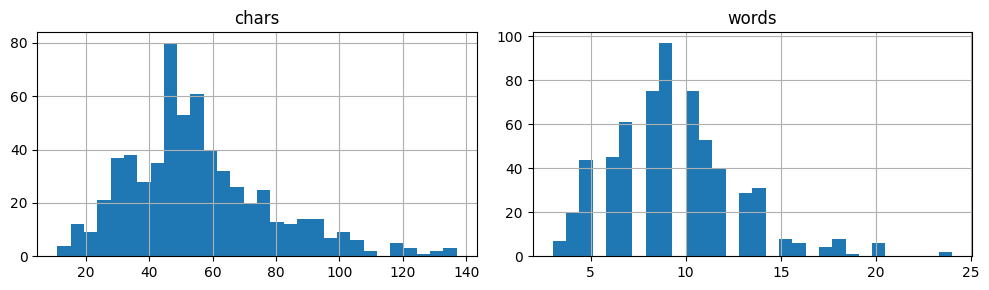

In [3]:
# Statement length distribution (in characters and rough word count)
facts['n_chars'] = facts['statement'].str.len()
facts['n_words'] = facts['statement'].str.split().str.len()
print(facts[['n_chars', 'n_words']].describe())

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
facts['n_chars'].hist(bins=30, ax=axes[0]); axes[0].set_title('chars')
facts['n_words'].hist(bins=30, ax=axes[1]); axes[1].set_title('words')
plt.tight_layout()

In [11]:
# A few true statements and a few false ones — eyeball for quality
print("=== TRUE ===")
for s in facts[facts.label == 1].sample(5).statement: print("  ", s)
print("\n=== FALSE ===")
for s in facts[facts.label == 0].sample(5).statement: print("  ", s)

=== TRUE ===
   The currency of Japan is the yen.
   Earthquakes are caused by the movement of tectonic plates.
   Osmosis is the movement of water across a selectively permeable membrane.
   The capital of the United States is Washington, D.C.
   The human skeleton provides support and protection for the body.

=== FALSE ===
   Osmosis is the prevention of water movement across a selectively permeable membrane.
   The largest fish in the world is the goldfish.
   The fastest bird in the world is the penguin.
   Fossils are the preserved remains or traces of organisms that live in the present.
   The human nose is located on the forehead.


**Things to look for / write down what you notice:**
- Is the label balance roughly 50/50? (yes/no, how skewed)
- Are the false statements actually obviously-false to you, or do some seem ambiguous?
- Is there a topical bias (lots of geography? lots of physics?) that might confound generalization?
- Statement length distribution — RepE training will produce ~1 activation per token-prefix,
  so longer statements contribute more rows. Are a few outliers going to dominate?

## negation.csv

In [12]:
neg = pd.read_csv(DATA_DIR / "negation.csv")
print(f"Rows: {len(neg)}")
print(f"\nlabel x form crosstab (expect 50/50/50/50):")
print(pd.crosstab(neg['label'], neg['form']))
print(f"\nSample 8 rows:")
print(neg.sample(8, random_state=0).to_string(index=False))

Rows: 200

label x form crosstab (expect 50/50/50/50):
form   aff  neg
label          
0       50   50
1       50   50

Sample 8 rows:
                                      statement  label form
                  Australia is not a continent.      0  neg
      The Eiffel Tower is not located in Paris.      0  neg
Sound does not travel faster than light in air.      1  neg
   The human heart does not have four chambers.      0  neg
         Muhammad Ali won Olympic gold in 1956.      0  aff
             Tokyo is not the capital of Japan.      0  neg
        The Nile River flows through Argentina.      0  aff
          The French word for red is not rouge.      0  neg


      count  mean       std  min  25%  50%  75%   max
form                                                 
aff   100.0  5.94  1.269852  3.0  5.0  6.0  7.0   9.0
neg   100.0  7.42  1.224167  4.0  7.0  8.0  8.0  10.0


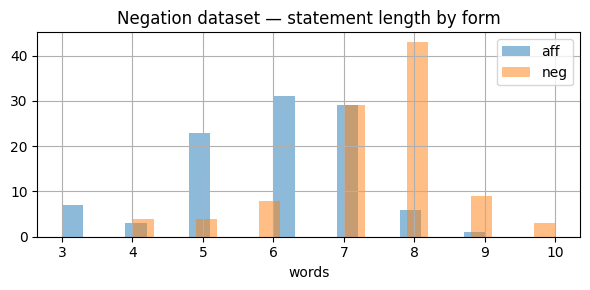

In [13]:
# Length distribution — these should be tighter than facts_true_false (Haiku
# was told to keep them <=15 words). If a few statements blow past that, we
# might want to filter — overly-long sentences will dominate the prefix-
# expansion if we apply Zou's truncation trick here too.
neg['n_words'] = neg['statement'].str.split().str.len()
print(neg.groupby('form')['n_words'].describe())

fig, ax = plt.subplots(figsize=(6, 3))
neg[neg.form == 'aff']['n_words'].hist(bins=20, alpha=0.5, label='aff', ax=ax)
neg[neg.form == 'neg']['n_words'].hist(bins=20, alpha=0.5, label='neg', ax=ax)
ax.legend(); ax.set_xlabel('words'); ax.set_title('Negation dataset — statement length by form')
plt.tight_layout()

In [14]:
# Look at a few full quads — verify the structure. Pair statements that share
# the first 3 words as a rough quad-grouping heuristic, then pick 3 random
# groups to print. (The CSV doesn't have an explicit quad_id; if we end up
# needing one for grouped train/test splitting we'll add it.)
neg['stem'] = neg['statement'].str.split().str[:3].str.join(' ')
quads = neg.groupby('stem').filter(lambda g: len(g) == 4)
n_full_quads = quads['stem'].nunique()
print(f"Detected {n_full_quads} full 4-row quads via 3-word stem grouping.")

import numpy as np
rng = np.random.default_rng(0)
for stem in rng.choice(quads['stem'].unique(), size=3, replace=False):
    print(f"\n--- {stem} ---")
    print(quads[quads.stem == stem][['statement', 'label', 'form']].to_string(index=False))

Detected 25 full 4-row quads via 3-word stem grouping.

--- Seventy-two divided by ---
                                         statement  label form
         Seventy-two divided by eight equals nine.      1  aff
        Seventy-two divided by eight equals eight.      0  aff
 Seventy-two divided by eight does not equal nine.      0  neg
Seventy-two divided by eight does not equal eight.      1  neg

--- The Rocky Mountains ---
                                            statement  label form
    The Rocky Mountains are in western North America.      1  aff
           The Rocky Mountains are in eastern Europe.      0  aff
The Rocky Mountains are not in western North America.      0  neg
       The Rocky Mountains are not in eastern Europe.      1  neg

--- The Italian word ---
                               statement  label form
    The Italian word for water is acqua.      1  aff
    The Italian word for water is fuoco.      0  aff
The Italian word for water is not acqua.      0  neg
T

**Things to look for here:**
- Are the negated-false rows actually false-after-negation? (Common Haiku
  failure: applying negation to a wrong-fact yielded label=0 instead of 1.)
- Are the affirmative pairs truly factual / counterfactual on the same frame?
  e.g. both should be about "the capital of France", not one about France and
  one about Spain.
- Topical diversity — does it look like ~15 geography, ~10 arithmetic, etc.
  per the prompt, or did the subagents collapse onto one topic?
- Length parity between aff and neg — neg should be ~3 words longer on
  average (due to "does not", "is not"). If they're very different beyond
  that, the probe could trivially learn "does this sentence contain 'not'?"
  rather than truth-vs-falsity.